# 01 - Exploratory data analysis

Goal: understand the patients, the labels and the audio before we build a model.

Run `python src/data_audit.py` and `python src/patient_table.py` first.
They create `outputs/audit_recordings.csv` and `outputs/patients.csv`.

In [1]:
import sys
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd
import soundfile as sf

sys.path.append(str(Path.cwd().parent / "src"))
from utils import get_dir, load_config

cfg = load_config()
DATA = get_dir(cfg, "data_dir")
OUT = get_dir(cfg, "output_dir")
FIG = get_dir(cfg, "figures_dir", create=True)

patients = pd.read_csv(OUT / "patients.csv", dtype={"Patient ID": str, "child_id": str})
audit = pd.read_csv(OUT / "audit_recordings.csv", dtype={"patient_id": str})
print(len(patients), "patients (visits),", patients.child_id.nunique(), "children,", len(audit), "recordings")

942 patients (visits), 872 children, 3163 recordings


## 1. Labels

The unit here is the **patient**, not the recording.

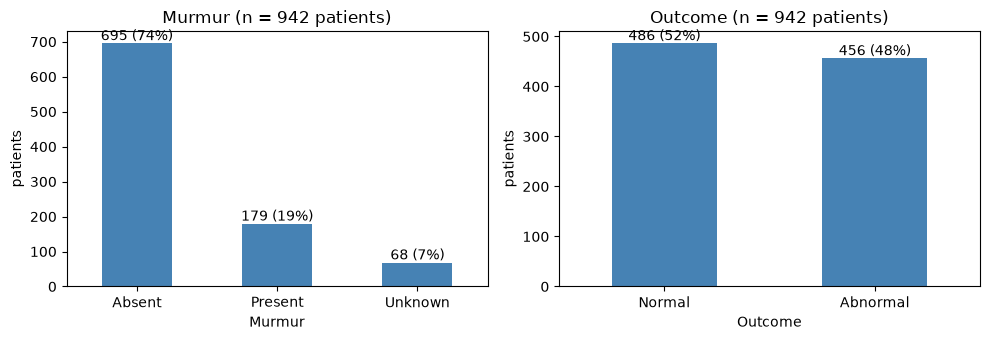

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["Murmur", "Outcome"]):
    counts = patients[col].value_counts()
    counts.plot.bar(ax=ax, color="steelblue")
    ax.set_title(f"{col} (n = {len(patients)} patients)")
    ax.set_ylabel("patients")
    for i, v in enumerate(counts):
        ax.text(i, v, f"{v} ({v / len(patients):.0%})", ha="center", va="bottom")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG / "eda_labels.png", dpi=120)
plt.show()

**Comment:** 74% of patients are Absent. A model that always says "Absent"
gets 74% accuracy, so accuracy alone is useless here. Outcome is almost balanced.

## 2. Age, sex and campaign

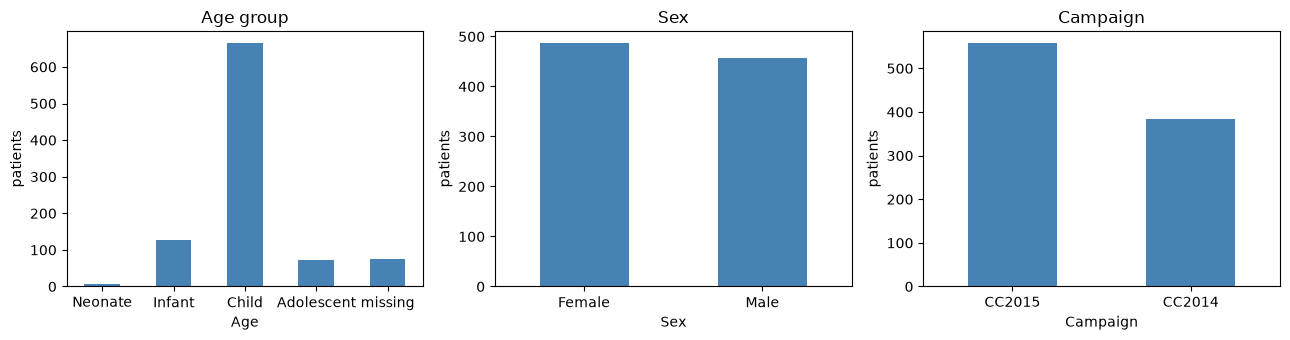

Pregnancy status  False  True 
Age                           
Adolescent           72      0
Child               664      0
Infant              126      0
Neonate               6      0
missing               4     70


In [3]:
age_order = ["Neonate", "Infant", "Child", "Adolescent", "missing"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
patients["Age"].fillna("missing").value_counts().reindex(age_order).plot.bar(ax=axes[0], color="steelblue")
patients["Sex"].value_counts().plot.bar(ax=axes[1], color="steelblue")
patients["Campaign"].value_counts().plot.bar(ax=axes[2], color="steelblue")
for ax, t in zip(axes, ["Age group", "Sex", "Campaign"]):
    ax.set_title(t); ax.set_ylabel("patients"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG / "eda_demographics.png", dpi=120)
plt.show()
print(pd.crosstab(patients["Age"].fillna("missing"), patients["Pregnancy status"]))

**Comment:** most patients are children. 70 of the 74 missing ages are
pregnant patients, so they are probably young adults with no age written.
This is real missing data, not structural.

## 3. Murmur by age group and campaign

In [4]:
print(pd.crosstab(patients["Age"].fillna("missing"), patients["Murmur"], normalize="index").round(2))
print()
print(pd.crosstab(patients["Campaign"], patients["Murmur"], normalize="index").round(2))

Murmur      Absent  Present  Unknown
Age                                 
Adolescent    0.74     0.22     0.04
Child         0.75     0.20     0.06
Infant        0.60     0.20     0.20
Neonate       0.67     0.17     0.17
missing       0.91     0.07     0.03

Murmur    Absent  Present  Unknown
Campaign                          
CC2014      0.78     0.16     0.05
CC2015      0.71     0.21     0.09


## 4. Recording duration by location

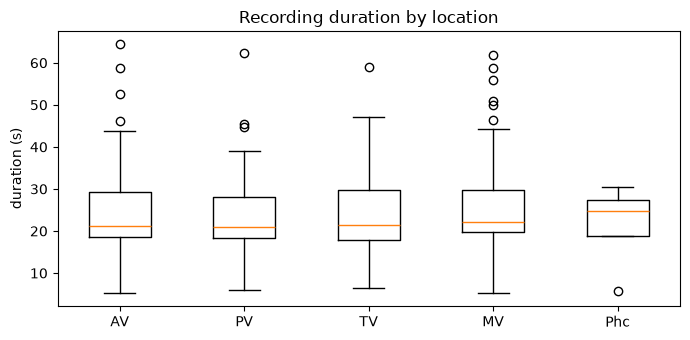

location
MV     861
AV     800
PV     766
TV     732
Phc      4
Name: count, dtype: int64
          count  mean   std  min   25%   50%   75%   max
location                                                
AV        800.0  22.5   7.5  5.2  18.5  21.2  29.3  64.5
MV        861.0  24.1   7.0  5.2  19.7  22.3  29.9  61.8
PV        766.0  22.0   6.9  6.0  18.3  21.1  28.0  62.2
Phc         4.0  21.4  10.9  5.7  18.9  24.9  27.5  30.4
TV        732.0  22.8   7.6  6.4  18.0  21.5  29.6  58.9


In [5]:
audit["location"] = audit["location"].astype(str)
order = ["AV", "PV", "TV", "MV", "Phc"]
order = [o for o in order if o in set(audit.location)]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([audit.loc[audit.location == o, "duration_s"] for o in order], tick_labels=order)
ax.set_ylabel("duration (s)"); ax.set_title("Recording duration by location")
plt.tight_layout()
plt.savefig(FIG / "eda_duration_by_location.png", dpi=120)
plt.show()
print(audit.location.value_counts())
print(audit.groupby("location").duration_s.describe().round(1))

**Comment:** durations go from about 5 to 65 s. Models need a fixed input size,
so we will cut every recording into 5 s windows. Most patients have the 4 main
locations (AV, PV, TV, MV). A few have repeated locations or Phc.

## 5. Murmur vs Outcome

In [6]:
ct = pd.crosstab(patients["Murmur"], patients["Outcome"], margins=True)
ct

Outcome,Abnormal,Normal,All
Murmur,,,
Absent,263,432,695
Present,150,29,179
Unknown,43,25,68
All,456,486,942


**Comment:** murmur and outcome are linked but not the same thing.
Many patients have no murmur but an Abnormal outcome. So a murmur detector is
not a full diagnosis tool.

## 6. Waveform and spectrogram: Absent, Present, noisy

- Absent: a recording from a patient without murmur.
- Present: the most audible location of a patient with a loud (III/VI) murmur.
- Noisy: the recording with the most clipped samples in the audit.

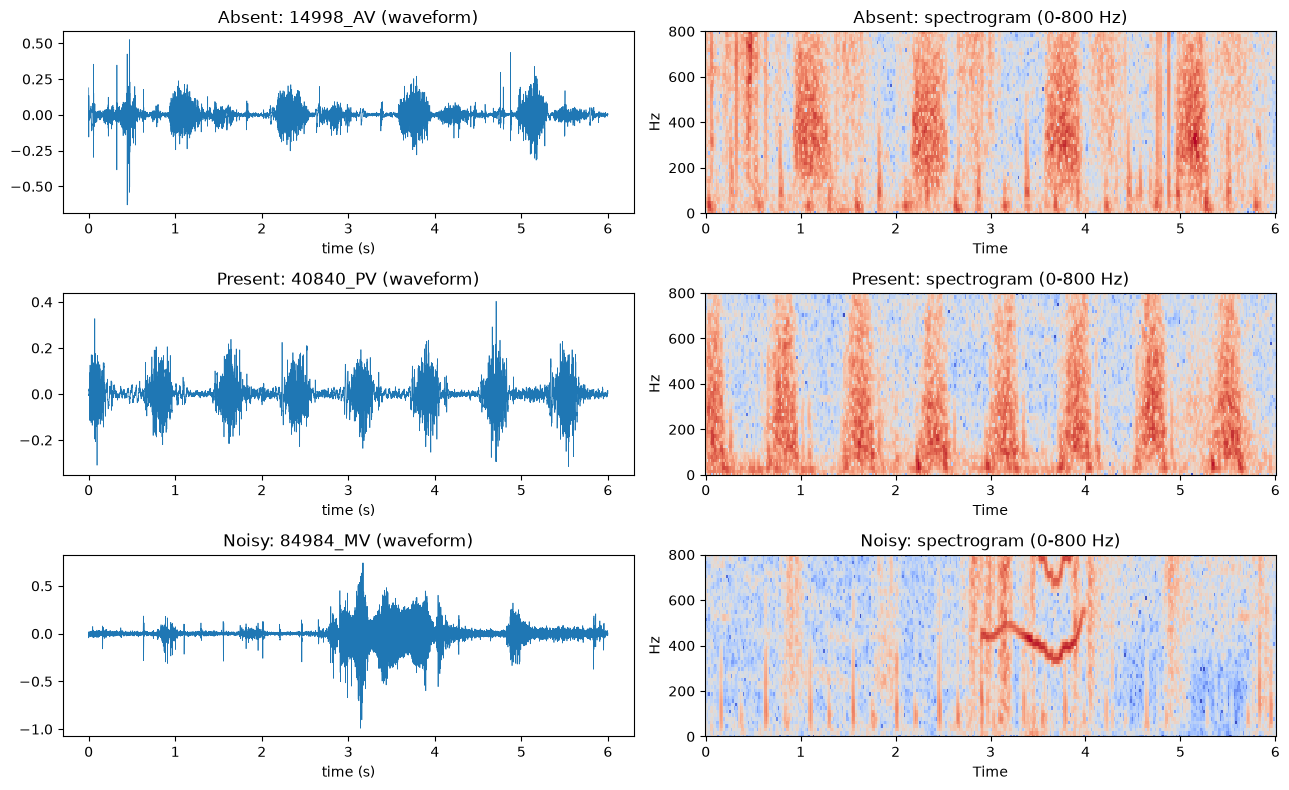

In [7]:
absent = patients[(patients.Murmur == "Absent")].iloc[0]
present = patients[(patients.Murmur == "Present") & (patients["Systolic murmur grading"] == "III/VI")].iloc[0]
examples = {
    "Absent": f"{absent['Patient ID']}_AV",
    "Present": f"{present['Patient ID']}_{present['Most audible location']}",
    "Noisy": audit.sort_values("clip_fraction").iloc[-1]["recording"],
}
fig, axes = plt.subplots(3, 2, figsize=(13, 8))
for row, (name, rec) in enumerate(examples.items()):
    x, sr = sf.read(DATA / f"{rec}.wav")
    x = x[: 6 * sr]  # first 6 seconds
    t = [i / sr for i in range(len(x))]
    axes[row, 0].plot(t, x, lw=0.5)
    axes[row, 0].set_title(f"{name}: {rec} (waveform)")
    axes[row, 0].set_xlabel("time (s)")
    S = librosa.amplitude_to_db(abs(librosa.stft(x, n_fft=256, hop_length=64)), ref=1.0)
    librosa.display.specshow(S, sr=sr, hop_length=64, x_axis="time", y_axis="hz", ax=axes[row, 1])
    axes[row, 1].set_ylim(0, 800)
    axes[row, 1].set_title(f"{name}: spectrogram (0-800 Hz)")
plt.tight_layout()
plt.savefig(FIG / "eda_examples.png", dpi=120)
plt.show()

**Comment:** by eye, the Absent and Present examples look similar:
both show regular heart beats. The murmur difference is small and hard to see,
so we need a model. The noisy example has a loud voice-like sound (crying or
speech) between 3 and 4 s, with a pitch line near 400 Hz. A filter cannot remove
it because it is inside the heart-sound band, so we will drop very noisy windows.

## Summary

- Unit of analysis = patient. 942 visits, 872 children (70 children were seen twice).
- Strong imbalance: Present is 19%. Use AUROC, PR-AUC, F1, sensitivity, not accuracy.
- 'nan' in murmur fields is structural. Real missing data: Age (74), Height (116), Weight (105).
- Durations vary a lot, so we use fixed 5 s windows.